# 04 — Explanations: what drives each remaining-life estimate?

**Stand-in data.** NASA turbofan simulation data stands in for rotating equipment. Not real field data.

**Phase 4 "done" line:** a function returning the top 3 drivers for any prediction, in plain words → `src.explain.top_drivers`.

**How it works:** SHAP starts from the fleet-average prediction and gives each feature a push (in cycles) up or down;
the pushes add up exactly to the engine's prediction. We use LightGBM's built-in exact TreeSHAP (`pred_contrib=True`),
then **sum the pushes of all features from the same sensor** (e.g. `s11_mean20`, `s11_slope10`, `s11_dev` → s11),
so explanations talk about sensors, not 141 feature names.

Sensor names come from NASA's C-MAPSS paper, Table 2 (see `configs/config.yaml` → `sensor_names`).

The model is trained on all 100 train engines and explains the **test engines**, which it never saw.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("interpreter:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import SENSORS, add_rul, add_test_rul, load_config, load_fd, near_constant_columns
from src.explain import by_sensor, contributions, sensor_of, top_drivers
from src.features import add_rolling_features
from src.rul import fit_lgbm

cfg = load_config()
CAP = cfg["data"]["rul_cap"]
NAMES = cfg["sensor_names"]
FIG_DIR = ROOT / cfg["paths"]["figures"]
train, test, true_rul = load_fd(cfg["data"]["subset"])
train, test = add_rul(train, CAP), add_test_rul(test, true_rul, CAP)
sensors = [s for s in SENSORS if s not in near_constant_columns(train, cfg["data"]["near_constant_std"])]
feat_args = (sensors, cfg["features"]["window_sizes"], cfg["anomaly"]["baseline_cycles"])
train, features = add_rolling_features(train, *feat_args)
test, _ = add_rolling_features(test, *feat_args)

model = fit_lgbm(train, features, cfg)
contrib = contributions(model, test[features])
pushes = by_sensor(contrib)

BLUE, GRAY, INK, INK2 = "#2a78d6", "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
})
gap = (contrib.sum(axis=1) - model.predict(test[features])).abs().max()
print(f"fleet-average starting point: {contrib['base'].iloc[0]:.1f} cycles")
print(f"check: base + pushes = prediction on all {len(test):,} test rows (max gap {gap:.1e} cycles)")

interpreter: C:\Users\A\Documents\NASA-project\.venv\Scripts\python.exe


fleet-average starting point: 86.8 cycles
check: base + pushes = prediction on all 13,096 test rows (max gap 2.6e-13 cycles)


## 1. Global importance: which sensors move the estimate most?

Average absolute push (cycles) per sensor over all test rows, next to Phase 1's trend strength
(|Spearman correlation with RUL| on train). Do the model and the raw data agree?

In [2]:
imp = pushes.abs().mean().sort_values(ascending=False).rename("mean_abs_push_cycles")
spearman = train[sensors].corrwith(train["rul"], method="spearman").abs()
glob = pd.DataFrame({
    "name": [NAMES[s]["name"] for s in imp.index],
    "mean_abs_push_cycles": imp,
    "share_of_total": imp / imp.sum(),
    "phase1_abs_spearman": spearman.reindex(imp.index),
})
rank_agree = glob["mean_abs_push_cycles"].drop("cycle").rank().corr(glob["phase1_abs_spearman"].drop("cycle").rank())
print(f"rank agreement between SHAP importance and Phase 1 trend strength (Spearman of ranks): {rank_agree:.2f}")
glob.round(3)

rank agreement between SHAP importance and Phase 1 trend strength (Spearman of ranks): 0.44


,name,mean_abs_push_cycles,share_of_total,phase1_abs_spearman
s4,LPT outlet temperature,7.221,0.174,0.702
s11,HPC outlet static pressure,6.323,0.152,0.718
cycle,engine age (cycles run),4.693,0.113,NaN
s15,bypass ratio,3.307,0.080,0.666
s12,fuel flow to HPC pressure ratio,3.232,0.078,0.693
s2,LPC outlet temperature,2.514,0.060,0.629
s14,corrected core speed,2.224,0.053,0.202
s9,core speed,2.221,0.053,0.322
s7,HPC outlet total pressure,1.827,0.044,0.679
s13,corrected fan speed,1.526,0.037,0.573


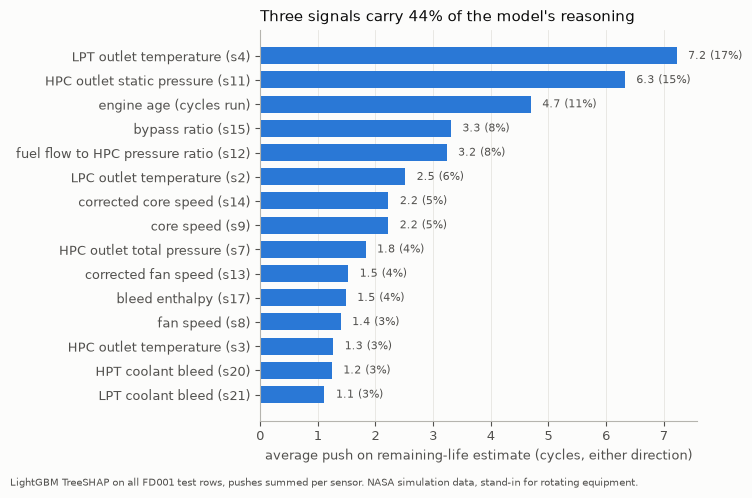

In [3]:
g = glob.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh([n if s == "cycle" else f"{n} ({s})" for s, n in zip(g.index, g.name)], g.mean_abs_push_cycles, color=BLUE, height=0.7)
for y, (v, sh) in enumerate(zip(g.mean_abs_push_cycles, g.share_of_total)):
    ax.text(v + 0.2, y, f"{v:.1f} ({sh:.0%})", va="center", color=INK2, fontsize=8)
top3 = glob.share_of_total.iloc[:3].sum()
ax.set(xlabel="average push on remaining-life estimate (cycles, either direction)")
ax.set_title(f"Three signals carry {top3:.0%} of the model's reasoning", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.text(0.01, -0.02, "LightGBM TreeSHAP on all FD001 test rows, pushes summed per sensor. "
         "NASA simulation data, stand-in for rotating equipment.", fontsize=7, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "shap_global.png", dpi=130, bbox_inches="tight")
plt.show()

## 2. Level or trend? Importance by feature type

Is the model reading *where a sensor is* (rolling mean, distance from healthy start) or *how fast it is changing* (slope)?

In [4]:
def feature_type(f: str) -> str:
    return "cycle" if f == "cycle" else f.split("_", 1)[1]

ftype = contrib.drop(columns="base").abs().mean().groupby(feature_type).sum().sort_values(ascending=False)
(ftype / ftype.sum()).rename("share_of_total").round(3).to_frame()

,share_of_total
dev,0.396
mean10,0.209
cycle,0.084
mean20,0.082
mean5,0.068
slope5,0.054
slope20,0.040
std20,0.036
slope10,0.014
std10,0.011


## 3. Twin sensors: does the model split credit?

Phase 1 found s9 and s14 correlate at 0.96, and s4 / s7 / s11 / s12 form a cluster.
If twins trade credit, their pushes would be negatively correlated row by row, and single-sensor importance would understate the pair.

In [5]:
print(f"s9 vs s14 push correlation across test rows: {pushes['s9'].corr(pushes['s14']):.2f}")
print(f"s9 + s14 combined share: {glob.loc[['s9', 's14'], 'share_of_total'].sum():.1%}")
cluster = ["s4", "s7", "s11", "s12"]
print(f"cluster {cluster} combined share: {glob.loc[cluster, 'share_of_total'].sum():.1%}")
pushes[cluster].corr().round(2)

s9 vs s14 push correlation across test rows: 0.77
s9 + s14 combined share: 10.7%
cluster ['s4', 's7', 's11', 's12'] combined share: 44.7%


,s4,s7,s11,s12
s4,1.00,0.52,0.63,0.52
s7,0.52,1.00,0.55,0.52
s11,0.63,0.55,1.00,0.60
s12,0.52,0.52,0.60,1.00


## 4. The done-line function on real engines

Three test engines at their last observed cycle: close to failure, mid-life, and healthy (by true RUL).

In [6]:
last = test.groupby("engine").tail(1).set_index("engine")
last["pred"] = model.predict(last[features])
base = contrib["base"].iloc[0]
for target in [15, 60, 120]:
    eng = (last.rul - target).abs().idxmin()
    row = last.loc[[eng]]
    print(f"Engine {eng}: predicted {row.pred.iloc[0]:.0f} cycles left (true {row.rul.iloc[0]}); fleet average {base:.0f}")
    for d in top_drivers(model, row, NAMES, k=3):
        print("   -", d["text"])
    print()

Engine 56: predicted 13 cycles left (true 15); fleet average 87
   - LPT outlet temperature (s4) is 7.52 degR above this engine's healthy start; this shortens the estimate by 15.8 cycles compared with the average engine.
   - HPC outlet static pressure (s11) is 0.43 psia above this engine's healthy start; this shortens the estimate by 15.2 cycles compared with the average engine.
   - Bypass ratio (s15) is 0.08 above this engine's healthy start; this shortens the estimate by 9.3 cycles compared with the average engine.

Engine 43: predicted 61 cycles left (true 59); fleet average 87
   - Fuel flow to HPC pressure ratio (s12) is 0.92 pps/psi below this engine's healthy start; this shortens the estimate by 7.4 cycles compared with the average engine.
   - HPC outlet static pressure (s11) is 0.28 psia above this engine's healthy start; this shortens the estimate by 6.8 cycles compared with the average engine.
   - HPC outlet total pressure (s7) is 1.71 psia below this engine's healthy sta

In [7]:
# structured form, as the API (Phase 6) and field note (Phase 7) will receive it
top_drivers(model, last.loc[[last.index[0]]], NAMES)

[{'sensor': 's4',
  'name': 'LPT outlet temperature',
  'effect_cycles': 8.4,
  'reading': -2.7,
  'text': "LPT outlet temperature (s4) is 2.7 degR below this engine's healthy start; this extends the estimate by 8.4 cycles compared with the average engine."},
 {'sensor': 's11',
  'name': 'HPC outlet static pressure',
  'effect_cycles': 7.5,
  'reading': -0.08,
  'text': "HPC outlet static pressure (s11) is 0.08 psia below this engine's healthy start; this extends the estimate by 7.5 cycles compared with the average engine."},
 {'sensor': 'cycle',
  'name': 'engine age (cycles run)',
  'effect_cycles': 3.4,
  'reading': 31,
  'text': 'Engine age (31 cycles run) extends the estimate by 3.4 cycles compared with the average engine.'}]

## 5. How much of each prediction do the top 3 explain?

The top 3 sensors are a summary, not the full story. Share of the total push (|sum of all pushes|) captured by the top 3, per test engine.

In [8]:
lp = by_sensor(contributions(model, last[features]))
top3_share = lp.abs().apply(lambda r: r.nlargest(3).sum() / r.sum(), axis=1)
print(top3_share.describe().round(2).to_string())

count    100.00
mean       0.51
std        0.06
min        0.38
25%        0.47
50%        0.51
75%        0.55
max        0.71


## 6. Conclusions

**Done line met:** `src.explain.top_drivers(model, row, sensor_names)` returns the top 3 drivers of any prediction as
structured data plus a plain-English sentence, e.g. for test engine 56 (predicted 13 cycles left, true 15):
> LPT outlet temperature (s4) is 7.52 degR above this engine's healthy start; this shortens the estimate by 15.8 cycles compared with the average engine.

1. **Two sensors lead:** LPT outlet temperature (s4, 17% of all pushes) and HPC outlet static pressure (s11, 15%), then engine age (11%). Together 44%.
2. **The model mostly reads "how far has this engine drifted from its own start".** Distance-from-healthy-start features carry 40% of all pushes and rolling means 36%; slopes only 11%, spread (std) 5%, age 8%. The Phase 2 idea (compare each engine with itself) is the single most-used feature type.
3. **Agreement with Phase 1 is only moderate** (rank correlation 0.44). Sensors that trend strongly in the raw data but carry the same information as others (s7, s20, s21) get small pushes: the model leans on one or two members of each correlated group.
4. **No sign of random credit-swapping between twin sensors.** Pushes of s9 and s14 move together (correlation 0.77), as do s4 / s7 / s11 / s12 (0.52–0.63); that cluster carries 45% combined. Read a single sensor's importance inside a cluster as shared with its twins.
5. **The top 3 are a summary, not the whole story:** they cover a median 51% of each engine's total push (range 38–71%). The rest is spread over the other 12 signals. The API should present them as "top 3 drivers", not "the cause".
6. **Pushes are relative to the average engine**, not to the engine's own past. A worn sensor can still "extend" the estimate if the engine is less worn than average (engine 26). The sentences say "compared with the average engine" to avoid that confusion.

**Limits**
- SHAP explains **the model**, not the physics. "s4 shortens the estimate" means the model relies on s4, not that s4 causes failure.
- Sensor names assume the data columns follow NASA's Table 2 order (supported by the data, see `configs/config.yaml`).
- Simulation data with one fault mode (HPC degradation); real equipment will have several competing causes.
